In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import load_wine
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

In [ ]:
#Distance and similarity calculations
def euclidean_distance(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return np.sqrt(np.sum((a - b) ** 2))


def manhattan_distance(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return np.sum(np.abs(a - b))


def cosine_similarity(a, b):
    a, b = np.asarray(a), np.asarray(b)

    denominator = np.linalg.norm(a) * np.linalg.norm(b)

    if denominator == 0:
        raise ValueError("Cosine similarity is undefined for a zero vector.")

    return np.dot(a, b) / denominator


first_vector = np.array([2, 3, 4])
second_vector = np.array([4, 5, 6])

distance_table = pd.DataFrame({
    "Measure": [
        "Euclidean distance",
        "Manhattan distance",
        "Cosine similarity"
    ],
    "Value": [
        euclidean_distance(first_vector, second_vector),
        manhattan_distance(first_vector, second_vector),
        cosine_similarity(first_vector, second_vector)
    ]
})

print(distance_table.round(4))

              Measure   Value
0  Euclidean distance  3.4641
1  Manhattan distance  6.0000
2   Cosine similarity  0.9946


In [ ]:
#Load dataset and standardize features
data = load_wine(as_frame=True)

X = data.data
y = data.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Samples:", X_scaled.shape[0])
print("Features:", list(X.columns))
print("Classes:", list(data.target_names))

Samples: 178
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


In [ ]:
#K-Means clustering
kmeans = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_metrics = {
    "Silhouette score": silhouette_score(X_scaled, kmeans_labels),
    "Adjusted Rand index": adjusted_rand_score(y, kmeans_labels),
    "Inertia": kmeans.inertia_,
    "Iterations": kmeans.n_iter_
}

print(pd.Series(kmeans_metrics).round(4))

print("\nCluster centers in standardized feature space:")

print(
    pd.DataFrame(
        kmeans.cluster_centers_,
        columns=X.columns
    ).round(3)
)

Silhouette score          0.2849
Adjusted Rand index       0.8975
Inertia                1277.9285
Iterations                7.0000
dtype: float64

Cluster centers in standardized feature space:
   alcohol  malic_acid    ash  alcalinity_of_ash  magnesium  total_phenols  \
0   -0.926      -0.394 -0.495              0.171     -0.492         -0.076   
1    0.165       0.872  0.187              0.524     -0.075         -0.979   
2    0.835      -0.304  0.365             -0.610      0.578          0.885   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity    hue  \
0       0.021                -0.034            0.058           -0.902  0.462   
1      -1.215                 0.726           -0.780            0.942 -1.165   
2       0.978                -0.562            0.580            0.171  0.474   

   od280/od315_of_diluted_wines  proline  
0                         0.271   -0.754  
1                        -1.292   -0.407  
2                         0.779    1.125  

In [ ]:
#Elbow method
inertias = []
silhouettes = []

k_values = range(2, 8)

for k in k_values:
    candidate = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = candidate.fit_predict(X_scaled)

    inertias.append(candidate.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

elbow_results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette": silhouettes
}).set_index("k")

print(elbow_results.round(4))

     Inertia  Silhouette
k                       
2  1658.7589      0.2593
3  1277.9285      0.2849
4  1175.4283      0.2602
5  1109.5127      0.2016
6  1046.0023      0.2372
7   981.5952      0.2036


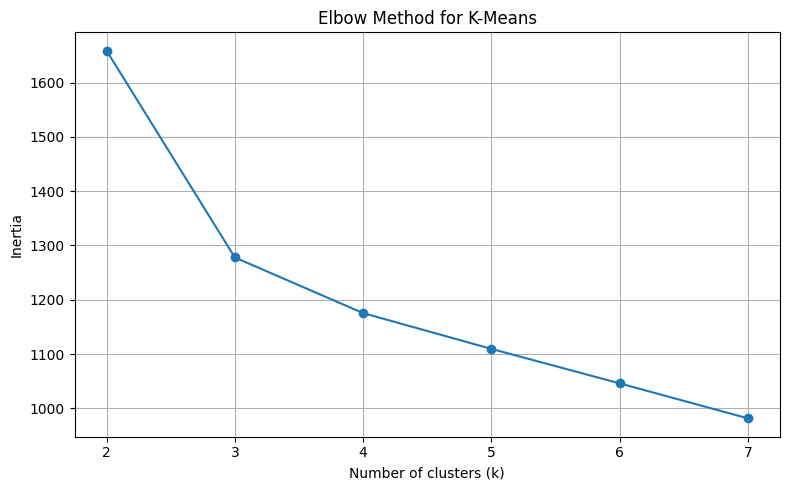

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

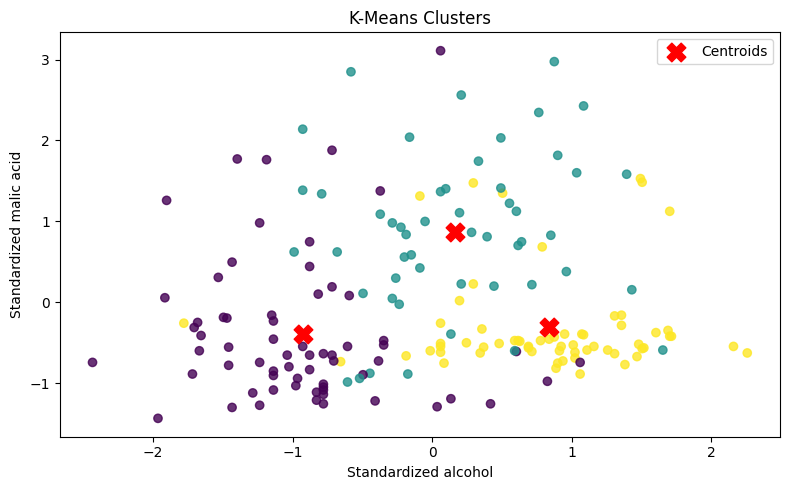

In [ ]:
#Visualize K-Means clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.8
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=180,
    label="Centroids"
)

plt.xlabel("Standardized alcohol")
plt.ylabel("Standardized malic acid")
plt.title("K-Means Clusters")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#Hierarchical clustering and linkage methods
linkage_methods = ["single", "complete", "average", "ward"]

hierarchical_results = []
hierarchical_labels = {}

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=method
    )

    labels = model.fit_predict(X_scaled)

    hierarchical_labels[method] = labels

    hierarchical_results.append({
        "Linkage": method,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Adjusted Rand": adjusted_rand_score(y, labels)
    })

hierarchical_table = pd.DataFrame(
    hierarchical_results
).set_index("Linkage")

print(hierarchical_table.round(4))

          Silhouette  Adjusted Rand
Linkage                            
single        0.1827        -0.0068
complete      0.2038         0.5771
average       0.1575        -0.0054
ward          0.2774         0.7899


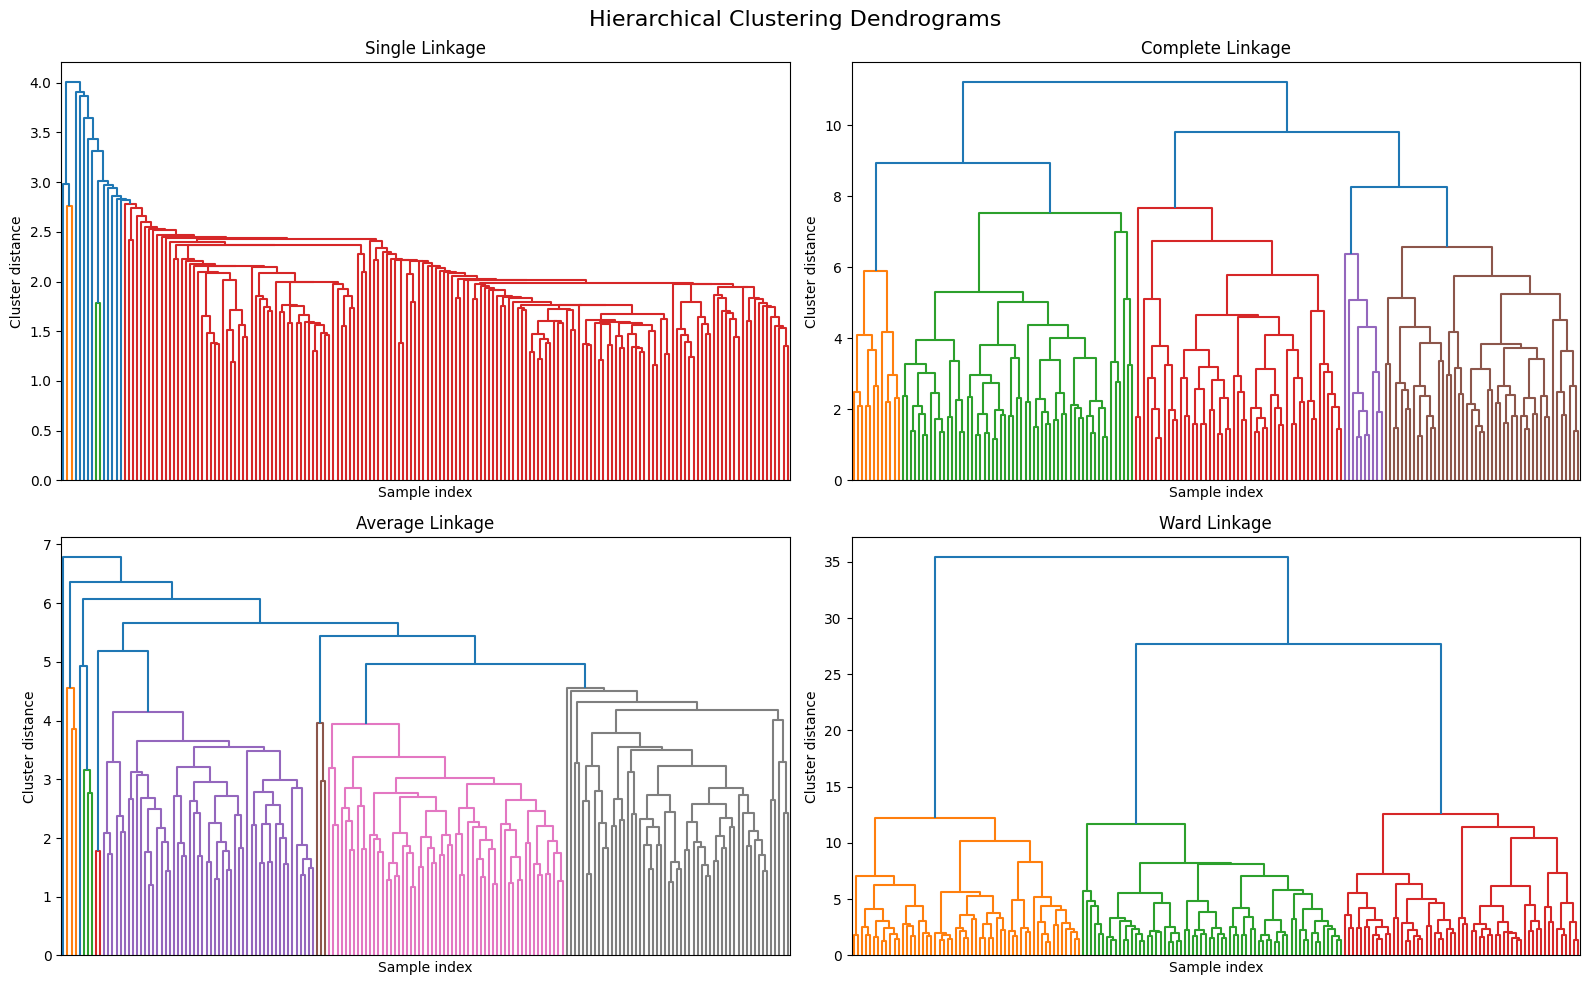

In [ ]:
#Construct dendrograms
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for axis, method in zip(axes.ravel(), linkage_methods):
    linkage_matrix = linkage(X_scaled, method=method)

    dendrogram(
        linkage_matrix,
        ax=axis,
        no_labels=True,
        color_threshold=None
    )

    axis.set_title(f"{method.title()} Linkage")
    axis.set_xlabel("Sample index")
    axis.set_ylabel("Cluster distance")

fig.suptitle(
    "Hierarchical Clustering Dendrograms",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
#Compare K-Means and hierarchical clustering
comparison = pd.DataFrame({
    "Method": [
        "K-Means",
        "Single Linkage",
        "Complete Linkage",
        "Average Linkage",
        "Ward Linkage"
    ],
    "Silhouette Score": [
        silhouette_score(X_scaled, kmeans_labels),
        *[
            silhouette_score(X_scaled, hierarchical_labels[method])
            for method in linkage_methods
        ]
    ],
    "Adjusted Rand Index": [
        adjusted_rand_score(y, kmeans_labels),
        *[
            adjusted_rand_score(y, hierarchical_labels[method])
            for method in linkage_methods
        ]
    ]
})

print(comparison.round(4))

             Method  Silhouette Score  Adjusted Rand Index
0           K-Means            0.2849               0.8975
1    Single Linkage            0.1827              -0.0068
2  Complete Linkage            0.2038               0.5771
3   Average Linkage            0.1575              -0.0054
4      Ward Linkage            0.2774               0.7899
